In [1]:
import os
import subprocess
from pathlib import Path
import tempfile

try:
    _printenv = subprocess.run(
        ['bash', '-c', 'source ~/.bashrc 2>/dev/null && printenv'],
        text=True, capture_output=True, timeout=10,
    ).stdout
    for _line in _printenv.splitlines():
        if '=' in _line:
            _k, _v = _line.split('=', 1)
            os.environ.setdefault(_k, _v)
except Exception:
    pass
if 'PDK_ROOT' in os.environ and 'PDK' in os.environ:
    os.environ.setdefault('PDKPATH', os.path.join(os.environ['PDK_ROOT'], os.environ['PDK']))

import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file,path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)

import gdsfactory as gf
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle
from glayout import MappedPDK, sky130, gf180
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring
from glayout.primitives.mimcap import mimcap_array
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

pdk = sky130
# Base parameters for PMOS and NMOS
encoder_config = {
    "pdk": pdk,
    "layout_rules": {
        "spacing": pdk.util_max_metal_seperation()+1.5,
        "routing_metal": "met2",
        "dummy_devices": False,
        "tie_layers": ("met2", "met1"),
        "sd_rmult": 1,
    },
}

nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

encoder_comp = Component(name="encoder")
encoder_comp.name = "encoder"
rules = encoder_config["layout_rules"]
spacing = rules["spacing"]
tie_layers = rules["tie_layers"]
sd_rmult = rules["sd_rmult"]

In [2]:
# ----------------------------------------------------------------------
# 1. Component Instantiation
# ----------------------------------------------------------------------

# --- Differential Pair (M1, M2): Long channel L=10u, W=0.28u ---
xm1 = nmos(pdk, width=0.5, length=10, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
xm2 = nmos(pdk, width=0.5, length=10, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult,**nmos_kwargs)

# --- Active Diode Loads (M3, M4): W=2u, L=0.28u ---
xm3 = pmos(pdk, width=2.0, length=0.28, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
xm4 = pmos(pdk, width=2.0, length=0.28, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)

# --- Output PMOS Current Mirrors (M5, M6, M7, M8): W=0.93u, L=1.86u ---
xm5 = pmos(pdk, width=0.5, length=0.94, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
xm8 = pmos(pdk, width=0.5, length=0.94, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
xm6 = pmos(pdk, width=0.5, length=0.94, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
xm7 = pmos(pdk, width=0.5, length=0.94, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)

# --- Tail Current Source & Bias Network (M9, M10, M11): W=0.28u, L=0.28u ---
xm9  = nmos(pdk, width=2.0, length=1.12, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
xm10 = nmos(pdk, width=0.5, length=0.28, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
xm11 = pmos(pdk, width=0.5, length=0.28, fingers=1, tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)

2026-10-30 19:50:02.814 | INFO     | gdsfactory.pdk:activate:337 - 'sky130' PDK is now active


In [3]:
# ----------------------------------------------------------------------
# 2. Structural Placement & Floorplanning
# -----------------------------------------------------------------------

# Set instance names
xm1.name  = "xm1"
xm2.name  = "xm2"
xm3.name  = "xm3"
xm4.name  = "xm4"
xm5.name  = "xm5"
xm6.name  = "xm6"
xm7.name  = "xm7"
xm8.name  = "xm8"
xm9.name  = "xm9"
xm10.name = "xm10"
xm11.name = "xm11"

# Create references for all devices in the top component
xm1_ref  = encoder_comp << xm1
xm2_ref  = encoder_comp << xm2
xm3_ref  = encoder_comp << xm3
xm4_ref  = encoder_comp << xm4
xm5_ref  = encoder_comp << xm5
xm6_ref  = encoder_comp << xm6
xm7_ref  = encoder_comp << xm7
xm8_ref  = encoder_comp << xm8
xm9_ref  = encoder_comp << xm9
xm10_ref = encoder_comp << xm10
xm11_ref = encoder_comp << xm11

#dynamic bbox
xm10_xy = evaluate_bbox(xm10)
xm9_xy  = evaluate_bbox(xm9)

xm1_xy  = evaluate_bbox(xm1)
xm2_xy  = evaluate_bbox(xm2)

xm8_xy  = evaluate_bbox(xm8)
xm5_xy  = evaluate_bbox(xm5)
xm3_xy  = evaluate_bbox(xm3)
xm11_xy = evaluate_bbox(xm11)
xm4_xy  = evaluate_bbox(xm4)
xm7_xy  = evaluate_bbox(xm7)
xm6_xy  = evaluate_bbox(xm6)


# Calculate Row Y-Coordinates dynamically to prevent Y-axis overlap
bottom_row_y = xm10_xy[1] / 2
middle_row_y = bottom_row_y + (xm10_xy[1] / 2) + spacing + (xm1_xy[1] / 2)
top_row_y    = middle_row_y + (xm1_xy[1] / 2) + spacing + (xm3_xy[1] / 2)


# # --- MIDDLE ROW: Differential Input NMOS Pair (xm1, xm2) ---
xm1_ref.move((0 + xm1_xy[0] / 2, middle_row_y + xm1_xy[1] / 2))
xm9_ref.move((xm1_ref.xmax + xm9_xy[0] / 2 + spacing, middle_row_y + xm9_xy[1] / 2))
xm10_ref.move((xm9_ref.xmax + xm10_xy[0] / 2 + spacing, middle_row_y + xm10_xy[1] / 2))
xm2_ref.move((xm10_ref.xmax + xm2_xy[0] / 2 + spacing, middle_row_y + xm2_xy[1] / 2))

# --- TOP ROW: PMOS Array (Alineación por la base) ---
xm3_ref.move((0 + xm3_xy[0] / 2, top_row_y + xm3_xy[1] / 2))
xm5_ref.move((xm3_ref.xmax + xm5_xy[0] / 2 + spacing, top_row_y + xm5_xy[1] / 2))
xm8_ref.move((xm5_ref.xmax + xm8_xy[0] / 2 + spacing, top_row_y + xm8_xy[1] / 2))
xm11_ref.move((xm8_ref.xmax + xm11_xy[0] / 2 + spacing, top_row_y + xm11_xy[1] / 2))
xm6_ref.move((xm11_ref.xmax + xm6_xy[0] / 2 + spacing, top_row_y + xm6_xy[1] / 2))
xm7_ref.move((xm6_ref.xmax + xm7_xy[0] / 2 + spacing, top_row_y + xm7_xy[1] / 2))
xm4_ref.move((xm7_ref.xmax + xm4_xy[0] / 2 + spacing, top_row_y + xm4_xy[1] / 2))

ComponentReference (parent Component "xm4", ports ['multiplier_0_gate_W', 'gate_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_top_met_W', 'multiplier_0_leftsd_array_row0_col0_bottom_layer_W', 'multiplier_0_leftsd_array_row0_col0_bottom_via_W', 'multiplier_0_leftsd_array_row0_col0_bottom_met_W', 'multiplier_0_leftsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_top_met_W', 'multiplier_0_leftsd_array_row1_col0_bottom_layer_W', 'multiplier_0_leftsd_array_row1_col0_bottom_via_W', 'multiplier_0_leftsd_array_row1_col0_bottom_met_W', 'multiplier_0_leftsd_array_row1_col0_top_met_W', 

2026-10-30 19:50:14.271 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/encoder.gds"}


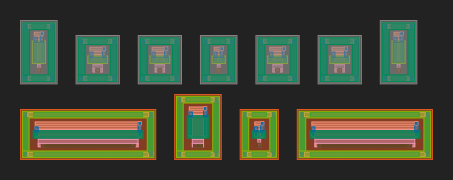

In [4]:
encoder_comp.show()
display_component(encoder_comp, scale=1, path=".")

In [5]:
# =========================================================================
# 3. ADD Vdd & VSS POWER RAILS, CONNECT SUPPLY NODES AND ADD PORTS
# =========================================================================
psize=(1,1)
# Calculate full horizontal span of the cell to draw supply rails
bbox = evaluate_bbox(encoder_comp)
top_y = encoder_comp.ymax + 1.0
bottom_y = encoder_comp.ymin - 2.0

#via m2m3
viam2m3 = via_stack(pdk, "met2", "met3", centered=True) #met2 is the bottom layer. met3 is the top layer.
#via m2m5
viam2m5 = via_stack(pdk, "met2", "met5", centered=True)
#via m2m4
viam2m4 = via_stack(pdk, "met2", "met4", centered=True)
#create via in every portss

# via en iex1
iex1_via = encoder_comp << viam2m3
iex1_via.move(xm8_ref.ports["multiplier_0_drain_E"].center).movex(1.5)

#via en iex2
iex2_via = encoder_comp << viam2m3
iex2_via.move(xm5_ref.ports["multiplier_0_drain_E"].center).movex(1.5)

#via en iex3
iex3_via = encoder_comp << viam2m3
iex3_via.move(xm7_ref.ports["multiplier_0_drain_E"].center).movex(1.5)

#via en iex4
iex4_via = encoder_comp << viam2m3
iex4_via.move(xm6_ref.ports["multiplier_0_drain_E"].center).movex(1.5)

#via en vin
vin_via = encoder_comp << viam2m3
vin_via.move(xm1_ref.ports["multiplier_0_gate_W"].center).movex(0.25)

#via en vin_neg
vin_neg_via = encoder_comp << viam2m3
vin_neg_via.move(xm2_ref.ports["multiplier_0_gate_W"].center).movex(0.25)


vias = [iex1_via, iex2_via, iex3_via, iex4_via, vin_neg_via, vin_via]

for via in vias:
    # 1. Instancias el cuadrado para la vía actual
    via_pin = encoder_comp << gf.components.rectangle(
        size=psize, 
        layer=pdk.get_layer("met2")
    )
    
    # 2. Mueves el cuadrado para que su centro coincida con el de la vía
    via_pin.move(via.center).movex(-evaluate_bbox(via_pin)[0]/2).movey(-evaluate_bbox(via_pin)[1]/2)


# Draw horizontal metal2 power rails
Vdd_rail = encoder_comp << gf.components.rectangle(size=(bbox[0]+4, 1.0),layer=pdk.get_layer("met3"))
Vdd_rail.move((-2, top_y))

Vss_rail = encoder_comp << gf.components.rectangle(size=(bbox[0]+4, 1.0), layer=pdk.get_layer("met3"))
Vss_rail.move((-2, bottom_y))

#via en vdd
vdd_via = encoder_comp << viam2m4
vdd_via.move((encoder_comp.xmax/2, top_y+0.5))

#via en vss
vss_via = encoder_comp << viam2m4
vss_via.move((bbox[0]/2, bottom_y + 0.5))


#----------- Adding snippet code to move all the placed components to the proper position, 
#----------- in order to set origin into 0,0
# Place this snippet after all your material polygones are placed, and before your ports are placed
bbox_all = encoder_comp.bbox[0]
for ref in encoder_comp.references:
    ref.movex(-1*bbox_all[0]).movey(-1*bbox_all[1])


2026-10-30 19:50:16.790 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/encoder.gds"}


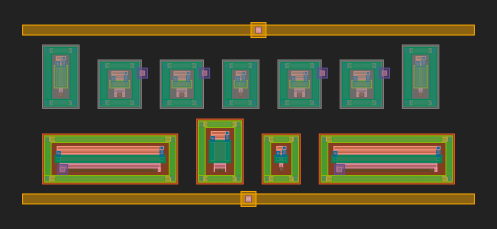

In [6]:
encoder_comp.show()
display_component(encoder_comp, scale=1, path=".")

In [7]:
# ----------------------------------------------------------------------
# 4. Interconnect Routing
# ----------------------------------------------------------------------

# Connect PMOS sources to avdd rail
encoder_comp << L_route(pdk, xm8_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm5_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm3_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm4_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm7_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm6_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm11_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])


# Connect NMOS BULKS TO AVSS
encoder_comp << L_route(pdk, xm9_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm10_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm1_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm2_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])

# Connecting the corresponding PMOS sources to avdd
encoder_comp << L_route(pdk,  xm8_ref.ports["multiplier_0_source_E"], xm8_ref.ports["tie_E_top_met_N"])  # SOURCE XM8
encoder_comp << L_route(pdk,  xm5_ref.ports["multiplier_0_source_E"], xm5_ref.ports["tie_E_top_met_N"])   # SOURCE XM5
encoder_comp << L_route(pdk,  xm3_ref.ports["multiplier_0_source_E"], xm3_ref.ports["tie_E_top_met_N"]) # SOURCE XM3
encoder_comp << L_route(pdk,  xm4_ref.ports["multiplier_0_source_E"], xm4_ref.ports["tie_E_top_met_N"]) # SOURCE XM4
encoder_comp << L_route(pdk,  xm7_ref.ports["multiplier_0_source_E"], xm7_ref.ports["tie_E_top_met_N"])   # SOURCE XM7
encoder_comp << L_route(pdk,  xm6_ref.ports["multiplier_0_source_E"], xm6_ref.ports["tie_E_top_met_N"]) # SOURCE XM6
encoder_comp << L_route(pdk,  xm11_ref.ports["multiplier_0_source_E"], xm11_ref.ports["tie_E_top_met_N"]) # SOURCE XM11

# Connecting the corresponding NMOS SOURCES TO AVSS
encoder_comp << L_route(pdk,  xm9_ref.ports["multiplier_0_source_E"], xm9_ref.ports["tie_E_top_met_N"]) #xm9
encoder_comp << L_route(pdk,  xm10_ref.ports["multiplier_0_source_E"], xm10_ref.ports["tie_E_top_met_N"]) #xm10

# # --- B. Node 'x' Connections (M1 Drain, M3 Gate/Drain, M5 Gate, M8 Gate) ---
# # Route M1 Drain to M3 Drain
encoder_comp << c_route(pdk, xm1_ref.ports["multiplier_0_drain_W"], xm3_ref.ports["multiplier_0_drain_W"],extension = 2)
encoder_comp << c_route(pdk, xm3_ref.ports["multiplier_0_drain_W"], xm3_ref.ports["multiplier_0_gate_W"], extension=2)
encoder_comp << straight_route(pdk, xm5_ref.ports["multiplier_0_gate_E"], xm8_ref.ports["multiplier_0_gate_W"])
encoder_comp << straight_route(pdk, xm3_ref.ports["multiplier_0_gate_E"], xm5_ref.ports["multiplier_0_gate_W"])


# # # --- C. Node 'y' Connections (M2 Drain, M4 Gate/Drain, M6 Gate, M7 Gate) ---
encoder_comp << c_route(pdk, xm2_ref.ports["multiplier_0_drain_E"], xm4_ref.ports["multiplier_0_drain_E"],extension=1.25)
encoder_comp << straight_route(pdk, xm6_ref.ports["multiplier_0_gate_E"], xm7_ref.ports["multiplier_0_gate_W"])
encoder_comp << c_route(pdk, xm4_ref.ports["multiplier_0_drain_E"], xm4_ref.ports["multiplier_0_gate_E"], extension=1.5)
encoder_comp << straight_route(pdk, xm7_ref.ports["multiplier_0_gate_E"], xm4_ref.ports["multiplier_0_gate_W"])

# # # --- D. Bias Network (net1) Routing ---
encoder_comp << c_route(pdk, xm10_ref.ports["multiplier_0_drain_E"],xm10_ref.ports["multiplier_0_gate_E"], extension=1.5)
encoder_comp << c_route(pdk, xm11_ref.ports["multiplier_0_drain_W"], xm11_ref.ports["multiplier_0_gate_W"], extension=1.5)
encoder_comp << c_route(pdk, xm11_ref.ports["multiplier_0_gate_E"], xm9_ref.ports["multiplier_0_gate_E"], extension=1.5)
encoder_comp << straight_route(pdk, xm9_ref.ports["multiplier_0_gate_E"], xm10_ref.ports["multiplier_0_gate_W"])

# #via XM10 XM11
# xm10_xm11_via = encoder_comp << viam2m3
# xm10_xm11_via.move(xm10_ref.ports["multiplier_0_drain_W"].center).movex(1.5).movey(2.5)
# encoder_comp << c_route(pdk, xm11_ref.ports["multiplier_0_gate_E"], xm10_xm11_via.ports["bottom_met_E"],extension=1.5)
# encoder_comp << c_route(pdk, xm10_ref.ports["multiplier_0_drain_W"], xm10_xm11_via.ports["bottom_met_W"], extension=2.5)


#create via xm1xm9
xm1_xm9_via = encoder_comp << viam2m3
#via XM1 und XM9
xm1_xm9_via.move(xm1_ref.ports["multiplier_0_source_E"].center).movex(2)
encoder_comp << straight_route(pdk, xm1_ref.ports["multiplier_0_source_E"], xm1_xm9_via.ports["bottom_met_W"])
encoder_comp << L_route(pdk, xm1_xm9_via.ports["top_met_N"], xm9_ref.ports["multiplier_0_drain_W"])

#create via xm2xm9 
xm2_xm9_via = encoder_comp << viam2m3
#via XM2 und XM9
xm2_xm9_via.move(xm2_ref.ports["multiplier_0_source_W"].center).movex(-2)
encoder_comp << straight_route(pdk, xm2_ref.ports["multiplier_0_source_E"], xm2_xm9_via.ports["bottom_met_W"])
encoder_comp << c_route(pdk, xm1_xm9_via.ports["top_met_N"], xm2_xm9_via.ports["top_met_N"], extension=3.5, cglayer="met2")

#Connect drain to iex_via for every port
encoder_comp << straight_route(pdk, xm5_ref.ports["multiplier_0_drain_E"], iex2_via.ports["bottom_met_W"])
encoder_comp << straight_route(pdk, xm8_ref.ports["multiplier_0_drain_E"], iex1_via.ports["bottom_met_W"])
encoder_comp << straight_route(pdk, xm7_ref.ports["multiplier_0_drain_E"], iex3_via.ports["bottom_met_W"])
encoder_comp << straight_route(pdk, xm6_ref.ports["multiplier_0_drain_E"], iex4_via.ports["bottom_met_W"])



ComponentReference (parent Component "straight_route_467bf7ae", ports ['route_W', 'route_N', 'route_E', 'route_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-30 19:50:28.015 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/encoder.gds"}


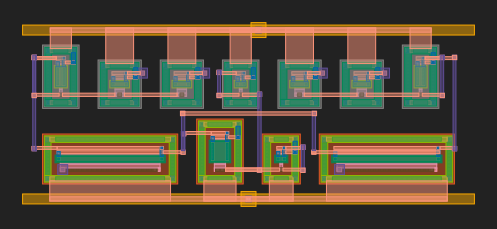

In [8]:
encoder_comp.show()
display_component(encoder_comp, scale=1, path=".")

In [9]:
# =========================================================================
# ADD PHYSICAL PINS AND LABELS FOR LVS
# =========================================================================

# Map port names to their source objects and properties
# Format: "pin_name": (source_object, orientation, port_layer, label_layer, mag)
pins_to_create = {
    "Vdd":     (vdd_via, 180, "met3", "met4_label", 1.5),
    "Vss":     (vss_via, 180, "met3", "met4_label", 1.5),
    "Vin":     (vin_via, 180, "met2", "met3_label", 1.5),
    "Vin_neg": (vin_neg_via, 180, "met2", "met3_label", 1.5),
    "Iex_1_i": (iex1_via, 270, "met2", "met3_label", 1.5),
    "Iex_2_i": (iex2_via, 270, "met2", "met3_label", 1.5),
    "Iex_3_i": (iex3_via, 270, "met2", "met3_label", 1.5),
    "Iex_4_i": (iex4_via, 270, "met2", "met3_label", 1.5)
}

for pin_name, (ref_obj, orient, p_layer, l_layer, mag) in pins_to_create.items():
    # Extract center position from the reference object
    center = ref_obj.center
    
    # 1. Add port
    encoder_comp.add_port(
        name=pin_name, 
        center=center, 
        width=1.0, 
        orientation=orient, 
        layer=pdk.get_layer(p_layer),  
        port_type="electrical"
    ) 

    # 2. Add text label on the corresponding label layer for net identity
    encoder_comp.add_label(
        text=pin_name, 
        position=center, 
        layer=pdk.get_glayer(l_layer), 
        magnification=mag
    )

2026-10-30 19:50:35.600 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/encoder.gds"}


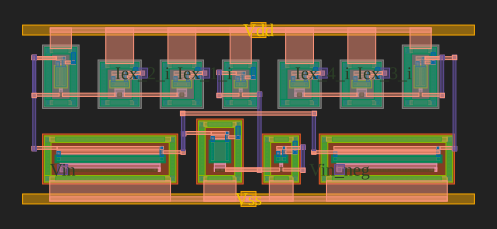

In [10]:
encoder_comp.show()
display_component(encoder_comp, scale=1, path=".")

In [11]:
encoder_comp.pprint_ports()

┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ name    ┃ width ┃ center           ┃ orientation ┃ layer    ┃ port_type  ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━┩
│ Vdd     │ 1.0   │ [23.63, 17.68]   │ 180         │ [70, 20] │ electrical │
│ Vss     │ 1.0   │ [22.63, 0.75]    │ 180         │ [70, 20] │ electrical │
│ Vin     │ 1.0   │ [4.02, 3.69]     │ 180         │ [69, 20] │ electrical │
│ Vin_neg │ 1.0   │ [31.74, 3.69]    │ 180         │ [69, 20] │ electrical │
│ Iex_1_i │ 1.0   │ [18.235, 13.365] │ 270         │ [69, 20] │ electrical │
│ Iex_2_i │ 1.0   │ [12.005, 13.365] │ 270         │ [69, 20] │ electrical │
│ Iex_3_i │ 1.0   │ [36.255, 13.365] │ 270         │ [69, 20] │ electrical │
│ Iex_4_i │ 1.0   │ [30.025, 13.365] │ 270         │ [69, 20] │ electrical │
└─────────┴───────┴──────────────────┴─────────────┴──────────┴────────────┘

In [12]:
drc_result = pdk.drc_magic(encoder_comp, encoder_comp.name)

2026-10-30 19:50:38.125 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmp3yge9uuw/encoder.gds'


using default pdk_root
Defaulting to stale magic_commands.tcl

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Loading "/tmp/tmp3yge9uuw/magic_commands.tcl" from command line.
Library written using GDS-II Release 6.0
Library name: library
Reading "encoder".
Reading "xm11".
Reading "straight_route_e03ec91e".
Reading "compass_layer69__20_size1__1$3".
Reading "L_route_aef96ca8".
Reading "xm5".
Reading "L

In [13]:
import os
from pathlib import Path
import tempfile

magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
design_name=encoder_comp.name
path_to_dir = "/foss/designs/libs/snn_analog/encoder/"

pex_path = path_to_dir + "spice/" + f"{encoder_comp.name}.spice"
gds_path = path_to_dir + "gds/" + f"{encoder_comp.name}.gds"
lef_path = path_to_dir + "lef/" + f"{encoder_comp.name}.lef"
encoder_comp.write_gds(str(gds_path))


magic_script_content = f"""
drc off            
gds flatglob *\\$\\$*
gds read {gds_path}

flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {str(pex_path)}
port Vdd use power
port Vss use ground
lef write {str(lef_path)}
exit
"""


with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
    magic_script_file.write(magic_script_content)
    magic_script_path = magic_script_file.name
    
magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
magic_subproc = subprocess.run(
    magic_cmd, 
    shell=True,
    check=True,
    capture_output=True
)

magic_subproc_code = magic_subproc.returncode
magic_subproc_out = magic_subproc.stdout.decode('utf-8')
print(magic_subproc_out)




2026-10-30 19:50:44.890 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/foss/designs/libs/snn_analog/encoder/gds/encoder.gds'



Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "encoder".
Reading "xm11".
Reading "straight_route_e03ec91e".
Reading "compass_layer69__20_size1__1$3".
Reading "L_route_aef96ca8".
Reading "xm5".
Reading "L_route_6bef0741".
Reading "compass_ac483f38".
Reading "rectangle_layer69

In [14]:
import glob
extensions = [
            "els"
            "*.gds",
            "*.ext",
            "*.res.ext",
            "*.lvs.rpt",
            "*_lvs.rpt",
            "*.nodes",
            "*.sim",
            "*.pex.spice",
            "*_pex.spice"
            ]
files_to_delete = []
for ext in extensions:
    files_to_delete.extend(glob.glob(ext))
    
# Delete the files
for file_path in files_to_delete:
    try:
        os.remove(file_path)
        print(f"Deleted: {file_path}")
    except OSError as e:
        print(f"Error deleting {file_path}: {e}")

Deleted: L_route_92775337.ext
Deleted: straight_route_81a3ad4b.ext
Deleted: xm7.ext
Deleted: L_route_960b5ac1.ext
Deleted: straight_route_42310da2.ext
Deleted: c_route_63ffc663.ext
Deleted: compass_layer69__20_size1__1$1.ext
Deleted: c_route_3e5e3415.ext
Deleted: c_route_5ead899b.ext
Deleted: compass_layer69__20_size1__1$3.ext
Deleted: rectangle_ac483f38$1.ext
Deleted: straight_route_467bf7ae.ext
Deleted: straight_route_e03ec91e.ext
Deleted: straight_route_1c6d17db.ext
Deleted: xm10.ext
Deleted: L_route_03bcd932.ext
Deleted: via_stack_05d99bde.ext
Deleted: L_route_91cdce63.ext
Deleted: L_route_979030a3.ext
Deleted: xm9.ext
Deleted: rectangle_layer69__20_size1__1$5.ext
Deleted: L_route_03e86ceb.ext
Deleted: L_route_dc33726b.ext
Deleted: compass_layer69__20_size1__1$5.ext
Deleted: straight_route_498d6896.ext
Deleted: c_route_bb7cea84.ext
Deleted: L_route_c6315dc6.ext
Deleted: rectangle_layer69__20_size1__1$3.ext
Deleted: L_route_b94d55dd.ext
Deleted: xm2.ext
Deleted: xm3.ext
Deleted: L_r

In [15]:
# Ejecutar LVS con Netgen usando el PDK sky130
pdk.lvs_netgen(
    layout=encoder_comp,   # tu layout exportado
    design_name=str(encoder_comp.name),   # nombre del diseño
    pdk_root=Path(os.environ['PDKPATH']),   # raíz del PDK
    lvs_setup_tcl_file=Path(os.environ['PDKPATH']) / "libs.tech" / "netgen" / f"{os.environ['PDK']}_setup.tcl",
    # Netlist extraído del layout (PEX/LVS)
    lvs_schematic_ref_file=Path(path_to_dir + "spice/" + "encoder.spice"),
    # Netlist de referencia (esquemático ideal)
    netlist=Path(path_to_dir  + "sch/" + "encoder_sch.spice"),
    # Carpeta donde se guarda el reporte .lvs.rpt
    output_file_path =  Path(str(path_to_dir))
)

2026-10-30 19:50:47.935 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmpdp_abqfr/encoder.gds'


using user specified pdk_root, will search for required files in the specified directory

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "encoder".
Reading "xm11".
Reading "straight_route_e03ec91e".
Reading "compass_layer69__20_size1__1$3".
Reading "L_route_aef96ca8".
Reading 

{'magic_subproc_code': 0,
 'netgen_subproc_code': 0,
 'result_str': 'LVS run succeeded\nErrors found in LVS report: /tmp/tmpdp_abqfr/encoder_lvs.rpt'}